# Malawi Inflation Forecasting Lab

**Comprehensive Research Notebook**

This single notebook walks through the entire workflow for the project, from raw data inspection to model evaluation.  All steps are fully documented, reproducible, and use only the packages listed in `requirements.txt`.  The notebook is organized into the following sections:
1. Data inspection
2. Data preparation (wide format, CPI rebasing flag, missing‑value handling)
3. Exploratory data analysis (plots, seasonality, stationarity tests)
4. Baseline Seasonal‑Naïve forecast
5. SARIMA modelling (expanding‑window)
6. XGBoost modelling (feature engineering, expanding‑window)
7. Hybrid SARIMA‑XGBoost forecast
8. Model evaluation (RMSE, MAE, MAPE, Directional Accuracy, bias)
9. Summary of results and next steps

All intermediate artefacts (cleaned data, forecasts, evaluation tables, figures) are written to the `outputs/` folder, which is ignored by Git via `.gitignore`.

## 1. Setup – Imports & Helper Functions

We load the required libraries and define a few utility functions that will be used throughout the notebook.  Keeping them here makes the notebook self‑contained, so no external `src/` module is required.

## Code Block 1: Import libraries and define helper utilities

In [6]:
import os, warnings
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
%matplotlib inline

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
import xgboost as xgb

# ------------------------------------------------------------------
# Helper utilities (self‑contained)
# ------------------------------------------------------------------
def load_raw_rbm(path='../data/Malawi_rbm_data.csv'):
    df = pd.read_csv(path)
    df['date'] = pd.to_datetime(df['date'])
    return df

def pivot_to_wide(df):
    wide = df.pivot_table(index='date', columns='indicator', values='value')
    wide = wide.sort_index()
    return wide

def add_cpi_rebase_flag(wide, threshold=0.15):
    cpi = wide['consumer_price_index']
    change = cpi.pct_change().abs()
    flag = (change > threshold).astype(int)
    wide['cpi_rebase_flag'] = flag
    return wide

def ensure_monthly_index(wide):
    full_idx = pd.date_range(start=wide.index.min(), end=wide.index.max(), freq='MS')
    wide = wide.reindex(full_idx)
    wide.index.name = 'date'
    return wide

def evaluate_metrics(y_true, y_pred):
    mask = ~np.isnan(y_true) & ~np.isnan(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    safe_true = np.where(y_true == 0, np.nan, y_true)
    mape = np.mean(np.abs((y_true - y_pred) / safe_true)) * 100
    true_change = np.diff(y_true, prepend=y_true[0])
    pred_change = np.diff(y_pred, prepend=y_pred[0])
    dir_acc = np.mean(np.sign(true_change) == np.sign(pred_change)) * 100
    bias = np.mean(y_pred - y_true)
    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'DirectionalAccuracy': dir_acc, 'Bias': bias}

# Output directories (created if missing)
os.makedirs('../outputs/forecasts', exist_ok=True)
os.makedirs('../outputs/tables', exist_ok=True)
os.makedirs('../outputs/figures', exist_ok=True)

## 2. Data Inspection
We first look at the raw RBM CSV to confirm its shape, column types and a quick glance at the first few rows.

## Code Block 2: Load raw data and display basic info

In [7]:
raw = load_raw_rbm()
print('Raw dataset shape:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw.head())

Raw dataset shape: (1117, 19)
Columns: ['date', 'indicator', 'value', 'unit', 'frequency', 'geography', 'region', 'district', 'market', 'commodity', 'source', 'source_url', 'category', 'raw_value', 'raw_date', 'raw_unit', 'raw_indicator', 'is_conflict', 'flagged']


,date,indicator,value,unit,frequency,geography,region,district,market,commodity,source,source_url,category,raw_value,raw_date,raw_unit,raw_indicator,is_conflict,flagged
0,2003-01-01,consumer_price_index,159.4,Index,monthly,Malawi,NaN,NaN,NaN,NaN,RBM,https://www.rbm.mw/Statistics/InflationRates/,Other,159.4,2003-01-01,Index,CPI Index (Overall),False,False
1,2003-01-01,food_inflation_rate,2.8,%,monthly,Malawi,NaN,NaN,NaN,NaN,RBM,https://www.rbm.mw/Statistics/InflationRates/,Macroeconomy,2.8,2003-01-01,%,Food Inflation (%),False,False
2,2003-01-01,inflation_rate,9.6,%,monthly,Malawi,NaN,NaN,NaN,NaN,RBM,https://www.rbm.mw/Statistics/InflationRates/,Macroeconomy,9.6,2003-01-01,%,"Inflation, consumer prices (annual %)",False,False
3,2003-01-01,non_food_inflation_rate,18.3,%,monthly,Malawi,NaN,NaN,NaN,NaN,RBM,https://www.rbm.mw/Statistics/InflationRates/,Macroeconomy,18.3,2003-01-01,%,Non-Food Inflation (%),False,False
4,2003-02-01,consumer_price_index,162.1,Index,monthly,Malawi,NaN,NaN,NaN,NaN,RBM,https://www.rbm.mw/Statistics/InflationRates/,Other,162.1,2003-02-01,Index,CPI Index (Overall),False,False


## 3. Data Preparation
* Parse dates (already done)
* Pivot to wide format (one column per indicator)
* Ensure a complete monthly index (introducing `NaN` where data are missing)
* Create a `cpi_rebase_flag` column that marks months where CPI jumps >15 % month‑to‑month (heuristic for rebasing).

## Code Block 3: Pivot, reindex, flag, and save prepared data

In [8]:
wide = pivot_to_wide(raw)
wide = ensure_monthly_index(wide)
wide = add_cpi_rebase_flag(wide)
# Save the prepared dataset for later use
wide.to_csv('../data/cleaned_inflation_prepped.csv', float_format='%.4f')
print('Prepared dataset saved to data/cleaned_inflation_prepped.csv')
display(wide.head())

Prepared dataset saved to data/cleaned_inflation_prepped.csv


indicator,bank_policy_rate,consumer_price_index,exchange_rate_usd_mwk_buying,exchange_rate_usd_mwk_selling,food_inflation_rate,fx:_eur/mwk_buying,fx:_eur/mwk_selling,fx:_gbp/mwk_buying,fx:_gbp/mwk_selling,fx:_zar/mwk_buying,fx:_zar/mwk_selling,inflation_rate,non_food_inflation_rate,cpi_rebase_flag
date,,,,,,,,,,,,,,
2003-01-01,NaN,159.4,NaN,NaN,2.8,NaN,NaN,NaN,NaN,NaN,NaN,9.6,18.3,0
2003-02-01,NaN,162.1,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,9.8,18.6,0
2003-03-01,NaN,158.0,NaN,NaN,7.7,NaN,NaN,NaN,NaN,NaN,NaN,10.2,13.7,0
2003-04-01,NaN,154.5,NaN,NaN,7.8,NaN,NaN,NaN,NaN,NaN,NaN,9.8,12.5,0
2003-05-01,NaN,151.7,NaN,NaN,5.7,NaN,NaN,NaN,NaN,NaN,NaN,9.0,15.9,0


## 4. Exploratory Data Analysis
We generate a suite of visualisations and statistical tests to understand the behaviour of the three inflation series.

## Code Block 4: Load series and create plots, tests, and highlights

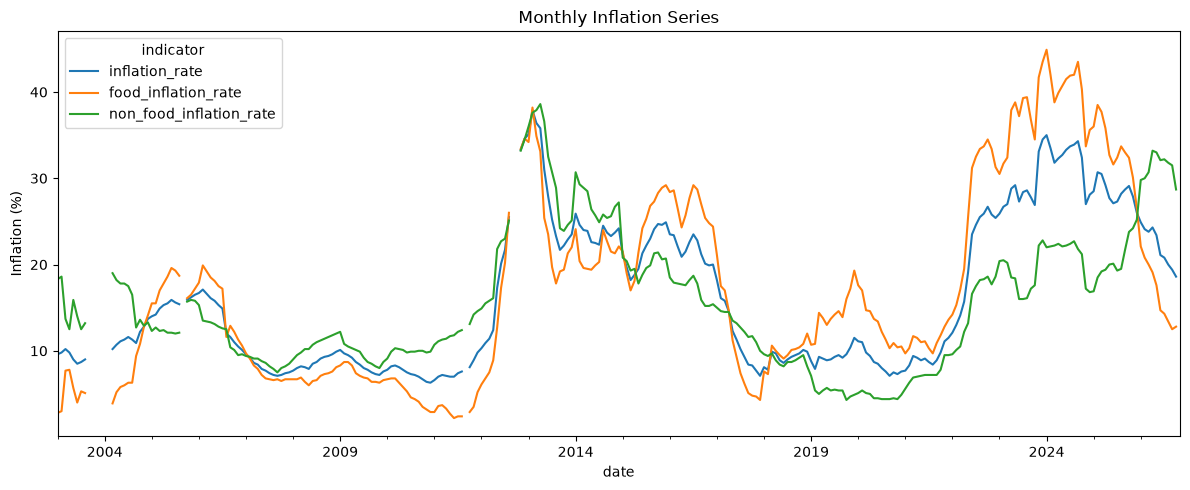

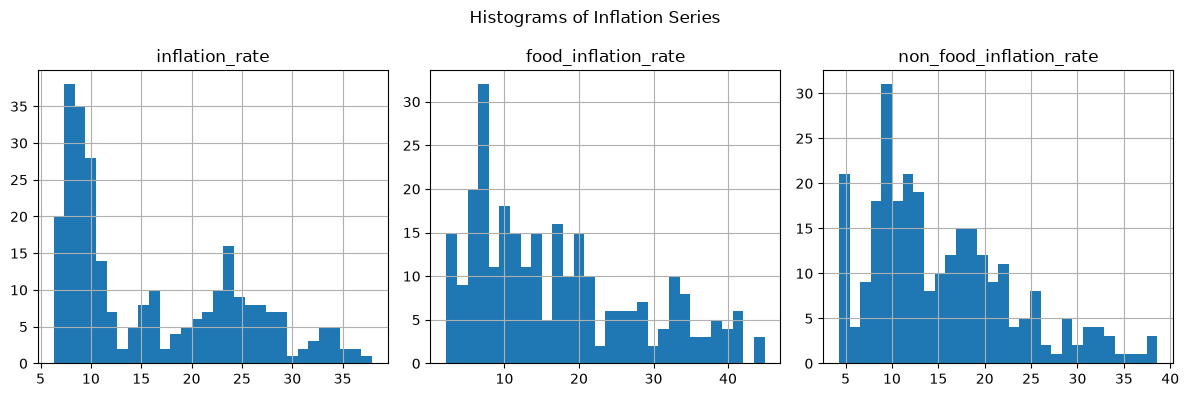

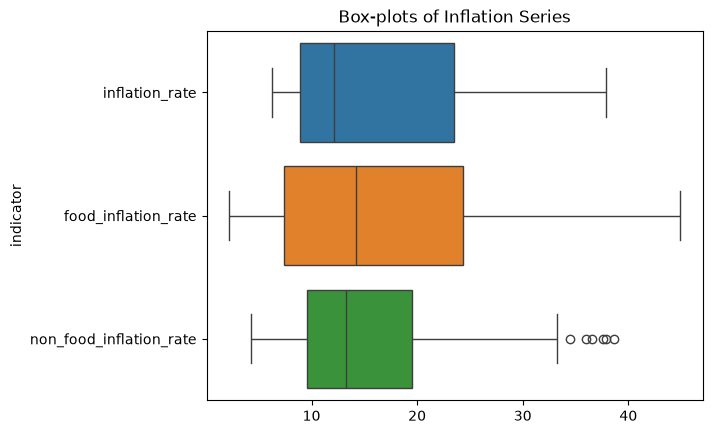

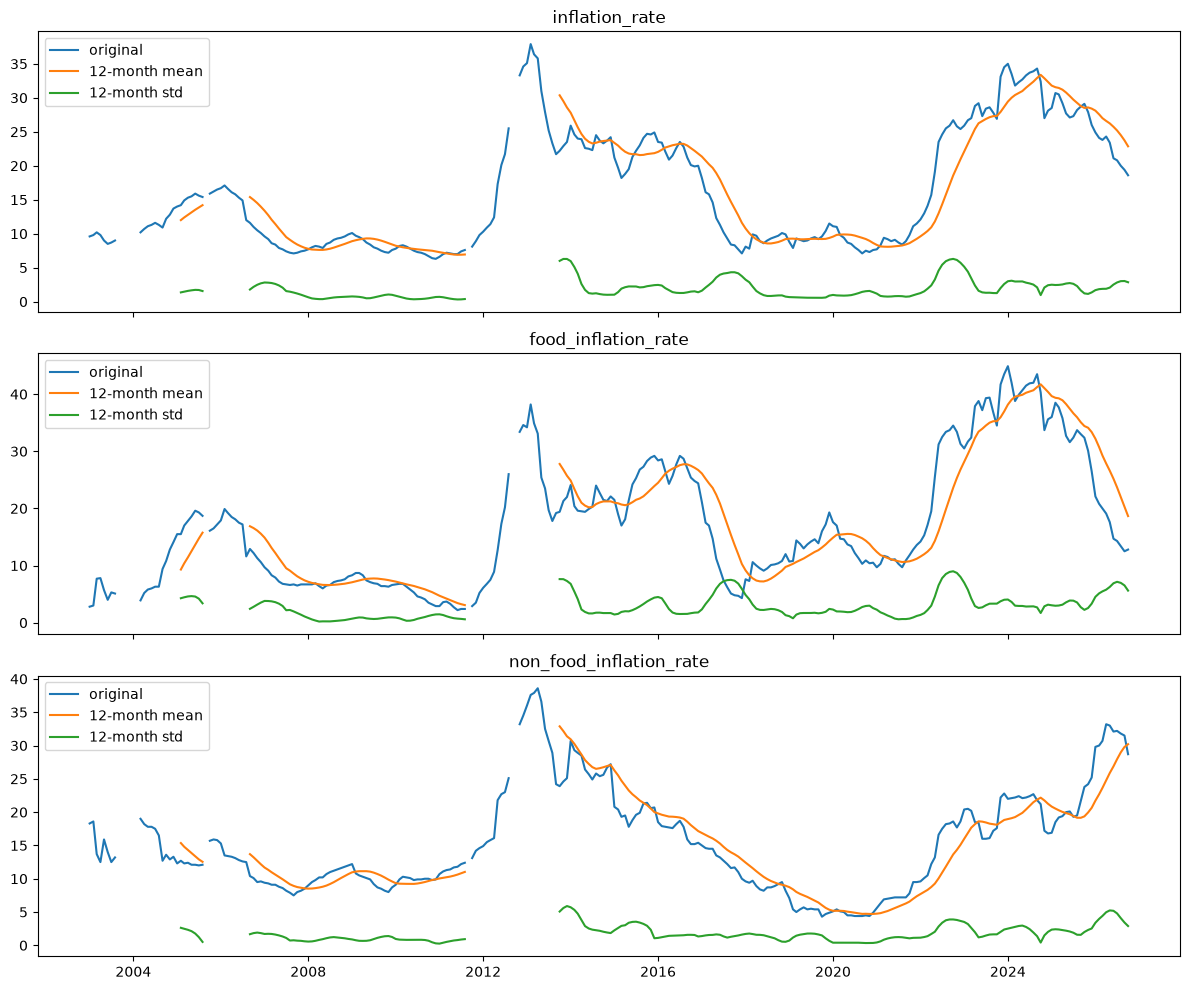

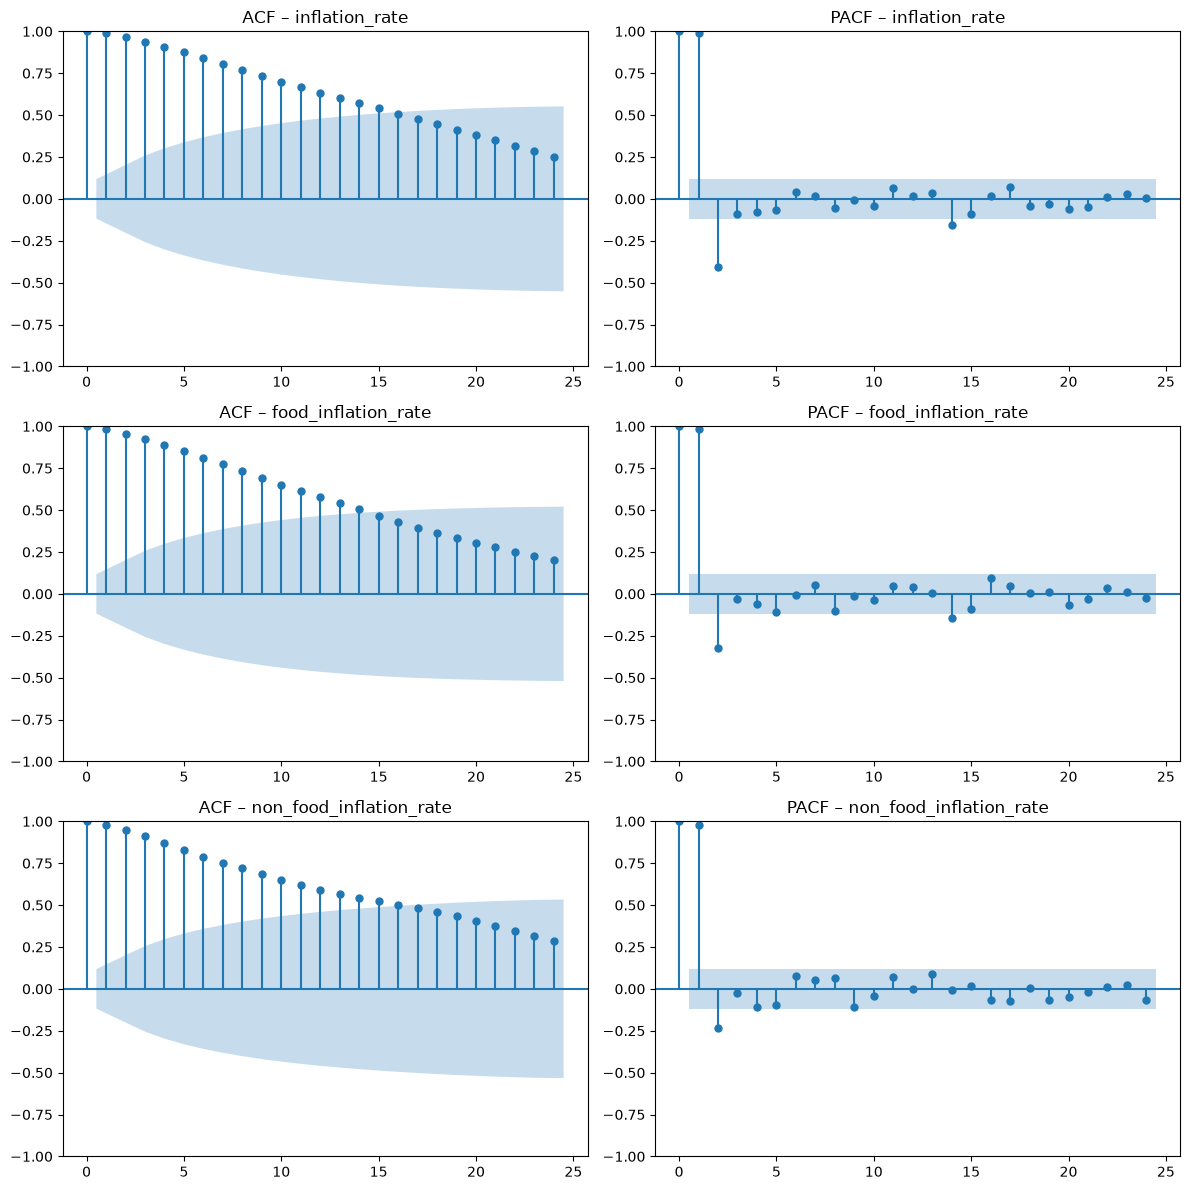


--- inflation_rate ---
ADF → {'ADF Statistic': -2.037674680386725, 'p‑value': 0.2703021786022918, 'Critical Values': {'1%': np.float64(-3.454355055831705), '5%': np.float64(-2.8721080938842976), '10%': np.float64(-2.572401325619835)}}
KPSS → {'KPSS Statistic': np.float64(0.6975934841878809), 'p‑value': np.float64(0.013764228710192642), 'Critical Values': {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}}

--- food_inflation_rate ---
ADF → {'ADF Statistic': -2.250539284520494, 'p‑value': 0.18841626016528884, 'Critical Values': {'1%': np.float64(-3.4544435065994437), '5%': np.float64(-2.8721468827772774), '10%': np.float64(-2.572422013959188)}}
KPSS → {'KPSS Statistic': np.float64(0.9923239487308242), 'p‑value': np.float64(0.01), 'Critical Values': {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}}

--- non_food_inflation_rate ---
ADF → {'ADF Statistic': -1.80295607832276, 'p‑value': 0.37899507356374956, 'Critical Values': {'1%': np.float64(-3.4547128138328875), '5%': np.flo

In [10]:
infl = wide[['inflation_rate', 'food_inflation_rate', 'non_food_inflation_rate']].copy()

# 4.1 Time‑series line plot (static)
infl.plot(figsize=(12,5), title='Monthly Inflation Series')
plt.ylabel('Inflation (%)')
plt.tight_layout()
plt.savefig('../outputs/figures/time_series.png')
plt.show()

# 4.2 Interactive Plotly version
fig = go.Figure()
for col in infl.columns:
    fig.add_trace(go.Scatter(x=infl.index, y=infl[col], mode='lines', name=col))
fig.update_layout(title='Interactive Inflation Time Series', xaxis_title='Date', yaxis_title='Inflation (%)')
fig.write_html('../outputs/figures/time_series_interactive.html')
fig.show()

# 4.3 Seasonal box‑plots (by calendar month)
infl_month = infl.copy()
infl_month['month'] = infl_month.index.month
fig = px.box(infl_month, x='month', y='inflation_rate', points='all', title='Headline Inflation by Month')
fig.write_html('../outputs/figures/seasonal_box_headline.html')
fig.show()

# 4.4 Histograms
infl.hist(bins=30, figsize=(12,4), layout=(1,3))
plt.suptitle('Histograms of Inflation Series')
plt.tight_layout()
plt.savefig('../outputs/figures/histograms.png')
plt.show()

# 4.5 Box‑plots (outlier detection)
sns.boxplot(data=infl, orient='h')
plt.title('Box‑plots of Inflation Series')
plt.savefig('../outputs/figures/boxplots.png')
plt.show()

# 4.6 Rolling 12‑month mean & std
roll_mean = infl.rolling(window=12).mean()
roll_std = infl.rolling(window=12).std()
fig, axes = plt.subplots(3,1,figsize=(12,10), sharex=True)
for i, col in enumerate(infl.columns):
    axes[i].plot(infl[col], label='original')
    axes[i].plot(roll_mean[col], label='12‑month mean')
    axes[i].plot(roll_std[col], label='12‑month std')
    axes[i].set_title(col)
    axes[i].legend()
plt.tight_layout()
plt.savefig('../outputs/figures/rolling_stats.png')
plt.show()

# 4.7 ACF / PACF (first 24 lags)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(3,2,figsize=(12,12))
for i, col in enumerate(infl.columns):
    plot_acf(infl[col].dropna(), lags=24, ax=axes[i,0])
    plot_pacf(infl[col].dropna(), lags=24, ax=axes[i,1])
    axes[i,0].set_title(f'ACF – {col}')
    axes[i,1].set_title(f'PACF – {col}')
plt.tight_layout()
plt.savefig('../outputs/figures/acf_pacf.png')
plt.show()

# 4.8 Stationarity tests (ADF & KPSS)
def adf(series):
    res = adfuller(series.dropna(), autolag='AIC')
    return {'ADF Statistic': res[0], 'p‑value': res[1], 'Critical Values': res[4]}

def kpss_test(series):
    res = kpss(series.dropna(), regression='c', nlags='auto')
    return {'KPSS Statistic': res[0], 'p‑value': res[1], 'Critical Values': res[3]}
for col in infl.columns:
    print('\n---', col, '---')
    print('ADF →', adf(infl[col]))
    print('KPSS →', kpss_test(infl[col]))

# 4.9 Highlight high‑inflation episodes (>15 %)
high = infl[infl['inflation_rate'] > 15]
fig = go.Figure()
fig.add_trace(go.Scatter(x=infl.index, y=infl['inflation_rate'], mode='lines', name='Headline'))
fig.add_trace(go.Scatter(x=high.index, y=high['inflation_rate'], mode='markers', name='>15%'))
fig.update_layout(title='Headline Inflation with High‑Inflation Episodes', xaxis_title='Date', yaxis_title='Inflation (%)')
fig.write_html('../outputs/figures/high_inflation.html')
fig.show()

## 5. Forecasting – Baseline Seasonal Naïve
The seasonal naïve forecast simply copies the observation from the same month one year earlier.

## Code Block 5: Generate Seasonal Naïve forecasts

In [19]:
# Define evaluation period
est_end = pd.Timestamp('2022-12-01')
eval_start = pd.Timestamp('2023-01-01')
eval_end = pd.Timestamp('2026-10-01')
eval_idx = pd.date_range(start=eval_start, end=eval_end, freq='MS')

def seasonal_naive(series, date):
    lag = date - pd.DateOffset(years=1)
    return series.get(lag, np.nan)

naive_forecasts = pd.DataFrame(index=eval_idx)
for col in infl.columns:
    ser = infl[col]
    naive_forecasts[col] = [seasonal_naive(ser, d) for d in eval_idx]

def last_value(series, date):
    """Forecast = most recent actual value available before `date`."""
    prev = series.loc[:date - pd.DateOffset(months=1)].dropna()
    return prev.iloc[-1] if len(prev) else np.nan

lastvalue_forecasts = pd.DataFrame(index=eval_idx)
for col in infl.columns:
    lastvalue_forecasts[col] = [last_value(infl[col], d) for d in eval_idx]

lastvalue_forecasts.to_csv('../outputs/forecasts/last_value.csv')
print('Last-value forecasts saved.')
naive_forecasts.to_csv('../outputs/forecasts/seasonal_naive.csv')
print('Seasonal Naïve forecasts saved.')

Last-value forecasts saved.
Seasonal Naïve forecasts saved.


## 6. SARIMA Forecasts (expanding‑window)
For each month in the evaluation period we fit a SARIMA model on all data up to the month before the forecast date.  Model order is selected automatically via AIC over a reasonable grid.

## Code Block 6: Auto‑select SARIMA order and generate forecasts

In [14]:
def auto_sarima(series, order_grid=None, seasonal_order_grid=None):
    if order_grid is None:
        order_grid = [(p, d, q) for p in range(0, 3) for d in range(0, 2) for q in range(0, 3)]
    if seasonal_order_grid is None:
        seasonal_order_grid = [(P, D, Q, 12) for P in range(0, 2) for D in range(0, 2) for Q in range(0, 2)]
    best_aic = np.inf
    best_cfg = None
    for order in order_grid:
        for sorder in seasonal_order_grid:
            try:
                model = SARIMAX(series, order=order, seasonal_order=sorder,
                                enforce_stationarity=False, enforce_invertibility=False)
                res = model.fit(disp=False)
                if res.aic < best_aic:
                    best_aic = res.aic
                    best_cfg = (order, sorder)
            except Exception:
                continue
    return best_cfg


def prepare_train(series, forecast_date):
    """Training data up to one month before forecast_date, with a regular monthly index."""
    train = series.loc[:forecast_date - pd.DateOffset(months=1)]
    first, last = train.first_valid_index(), train.last_valid_index()
    if first is None or last is None:
        return None, None
    train = train.loc[first:last].asfreq('MS')
    return train, last


def sarima_forecast(series, forecast_date, cfg=None, min_obs=36):
    train, last = prepare_train(series, forecast_date)
    if train is None or len(train.dropna()) < min_obs:
        return np.nan

    if cfg is None:
        cfg = auto_sarima(train)
    if cfg is None:
        return np.nan
    order, sorder = cfg

    try:
        model = SARIMAX(train, order=order, seasonal_order=sorder,
                        enforce_stationarity=False, enforce_invertibility=False)
        res = model.fit(disp=False)
        steps = (forecast_date.year - last.year) * 12 + (forecast_date.month - last.month)
        steps = max(steps, 1)
        return res.get_forecast(steps=steps).predicted_mean.iloc[-1]
    except Exception:
        return np.nan


# Make sure the index is a regular monthly DatetimeIndex
infl = ensure_monthly_index(infl)
eval_idx = pd.DatetimeIndex(eval_idx)

sarima_forecasts = pd.DataFrame(index=eval_idx)
sarima_cfgs = {}

for col in infl.columns:
    ser = infl[col]

    # Choose the order once per column, using data up to the first evaluation date
    first_train, _ = prepare_train(ser, eval_idx[0])
    if first_train is None or len(first_train.dropna()) < 36:
        print(f'{col}: not enough data, skipped')
        sarima_forecasts[col] = np.nan
        continue

    cfg = auto_sarima(first_train)
    sarima_cfgs[col] = cfg
    print(f'{col}: selected {cfg}')

    # Refit with the fixed order at each evaluation date
    sarima_forecasts[col] = [sarima_forecast(ser, d, cfg=cfg) for d in eval_idx]

sarima_forecasts.to_csv('../outputs/forecasts/sarima.csv')
print('SARIMA forecasts saved.')

inflation_rate: selected ((2, 0, 2), (0, 1, 1, 12))
food_inflation_rate: selected ((2, 0, 2), (1, 1, 1, 12))
non_food_inflation_rate: selected ((2, 1, 2), (1, 0, 1, 12))
SARIMA forecasts saved.


## 7. XGBoost Forecasts (expanding‑window)
We engineer lagged values, rolling statistics, month‑of‑year dummies and the CPI rebasing flag.  For each forecast origin we train on the available history and predict one month ahead.

## Code Block 7: Feature engineering and XGBoost forecasts

In [15]:
def create_features(df, target_col, max_lag=12):
    s = df[target_col]
    X = pd.DataFrame(index=df.index)

    # Lag features (only past values)
    for lag in range(1, max_lag + 1):
        X[f'{target_col}_lag{lag}'] = s.shift(lag)

    # Rolling stats, shifted by 1 so the current month is NOT included
    X[f'{target_col}_roll_mean'] = s.shift(1).rolling(window=12).mean()
    X[f'{target_col}_roll_std'] = s.shift(1).rolling(window=12).std()

    # Calendar month dummies (always m_2 ... m_12 so columns never change)
    months = pd.Series(df.index.month, index=df.index)
    month_dummies = pd.get_dummies(months, prefix='m', drop_first=True).astype(float)
    month_dummies = month_dummies.reindex(columns=[f'm_{m}' for m in range(2, 13)], fill_value=0.0)
    X = pd.concat([X, month_dummies], axis=1)

    # CPI rebasing flag, shifted so it only uses past information
    if 'cpi_rebase_flag' in df.columns:
        X['cpi_rebase_flag'] = df['cpi_rebase_flag'].shift(1)

    X['target'] = s
    return X


def xgb_forecast(feature_df, forecast_date, min_train=36):
    if forecast_date not in feature_df.index:
        return np.nan

    # Training data ends one month before forecast_date
    train_end = forecast_date - pd.DateOffset(months=1)
    train_df = feature_df.loc[:train_end].dropna()
    if len(train_df) < min_train:
        return np.nan

    X_train = train_df.drop(columns=['target'])
    y_train = train_df['target']

    # Features for the forecast month (target is not needed here)
    X_pred = feature_df.loc[[forecast_date]].drop(columns=['target'])
    if X_pred.isna().any().any():
        return np.nan

    model = xgb.XGBRegressor(
        objective='reg:squarederror',
        n_estimators=500,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method='hist',
        n_jobs=2,
        random_state=42,
    )
    model.fit(X_train, y_train)
    return float(model.predict(X_pred)[0])


eval_idx = pd.DatetimeIndex(eval_idx)
xgboost_forecasts = pd.DataFrame(index=eval_idx)

# Align the CPI flag to the same monthly index as infl
cpi_flag = wide['cpi_rebase_flag'].reindex(infl.index).fillna(0)

for col in infl.columns:
    full_df = pd.DataFrame({col: infl[col], 'cpi_rebase_flag': cpi_flag})
    feat_df = create_features(full_df, col)
    xgboost_forecasts[col] = [xgb_forecast(feat_df, d) for d in eval_idx]
    print(f'{col}: done')

xgboost_forecasts.to_csv('../outputs/forecasts/xgboost.csv')
print('XGBoost forecasts saved.')

inflation_rate: done
food_inflation_rate: done
non_food_inflation_rate: done
XGBoost forecasts saved.


## 8. Hybrid SARIMA + XGBoost Forecast
We first obtain SARIMA forecasts, compute the residuals, then train an XGBoost model on those residuals (using the same feature set as in the pure XGBoost step).  The final hybrid forecast is the SARIMA forecast plus the predicted residual.

## Code Block 8: Build hybrid forecasts using SARIMA residuals and XGBoost

In [16]:
def insample_residuals(series, end_date, cfg, burn=13):
    """One-step in-sample SARIMA residuals using data up to end_date - 1 month."""
    train, _ = prepare_train(series, end_date)
    order, sorder = cfg
    res = SARIMAX(train, order=order, seasonal_order=sorder,
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    resid = res.resid.copy()
    resid.iloc[:burn] = np.nan          # drop unstable diffuse-initialisation residuals
    return resid


eval_idx = pd.DatetimeIndex(eval_idx)
hybrid_forecasts = pd.DataFrame(index=eval_idx)
cpi_flag = wide['cpi_rebase_flag'].reindex(infl.index).fillna(0)

for col in infl.columns:
    cfg = sarima_cfgs.get(col)
    sarima_series = sarima_forecasts[col]
    if cfg is None or sarima_series.isna().all():
        hybrid_forecasts[col] = np.nan
        print(f'{col}: no SARIMA forecasts, skipped')
        continue

    actual = infl[col]

    # Residual history: in-sample before the evaluation start, out-of-sample after
    resid_full = pd.Series(np.nan, index=infl.index, dtype='float64')
    ins = insample_residuals(actual, eval_idx[0], cfg)
    resid_full.loc[ins.index] = ins.values
    resid_full.loc[eval_idx] = (actual.reindex(eval_idx) - sarima_series).values

    resid_df = pd.DataFrame({'residual': resid_full, 'cpi_rebase_flag': cpi_flag})
    feat_resid = create_features(resid_df, 'residual')

    # Expanding-window residual forecasts (xgb_forecast only uses data before d)
    pred_resid = np.array([xgb_forecast(feat_resid, d) for d in eval_idx])

    # Hybrid = SARIMA forecast + predicted residual (falls back to SARIMA if no residual forecast)
    hybrid_forecasts[col] = sarima_series.values + np.nan_to_num(pred_resid, nan=0.0)
    print(f'{col}: done')

hybrid_forecasts.to_csv('../outputs/forecasts/hybrid.csv')
print('Hybrid forecasts saved.')

inflation_rate: done
food_inflation_rate: done
non_food_inflation_rate: done
Hybrid forecasts saved.


## 9. Model Evaluation
We load all forecast files, align them with the actual inflation series, compute a consistent set of metrics, and summarise the results in a table.  Interactive Plotly figures are also generated.

## Code Block 9: Load forecasts, compute metrics, and generate plots

In [ ]:
# Actual series for the evaluation period
actual = infl.reindex(eval_idx)

def load_forecast(name):
    path = f'../outputs/forecasts/{name}.csv'
    if not os.path.exists(path):
        print(f'WARNING: {path} not found, skipping')
        return None
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    return df.reindex(eval_idx)

files = {
    'SeasonalNaive': 'seasonal_naive',
    'LastValue': 'last_value',
    'SARIMA': 'sarima',
    'XGBoost': 'xgboost',
    'Hybrid': 'hybrid',
}

forecasts = {}
for label, fname in files.items():
    df = load_forecast(fname)
    if df is not None:
        forecasts[label] = df

# Score every model on the SAME months (where actual and all models have values)
metrics = []
for col in infl.columns:
    valid = actual[col].notna()
    for pred_df in forecasts.values():
        valid &= pred_df[col].notna()

    print(f'{col}: {valid.sum()} common evaluation months')
    if valid.sum() < 3:
        print(f'  not enough common months for {col}, skipped')
        continue

    y_true = actual[col][valid].values.astype(float)
    for model_name, pred_df in forecasts.items():
        y_pred = pred_df[col][valid].values.astype(float)
        res = evaluate_metrics(y_true, y_pred)
        res.update({'Model': model_name, 'Indicator': col})
        metrics.append(res)

metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv('../outputs/tables/model_comparison.csv', index=False)
print('Evaluation table saved to outputs/tables/model_comparison.csv')
display(metrics_df.round(3))

# 9.1 RMSE bar chart
fig = px.bar(metrics_df, x='Indicator', y='RMSE', color='Model', barmode='group',
             title='RMSE by Model and Indicator')
fig.write_html('../outputs/figures/rmse_bar.html')
fig.show()

# 9.2 Forecast vs actual for each model
for model_name, pred_df in forecasts.items():
    fig = go.Figure()
    for col in infl.columns:
        fig.add_trace(go.Scatter(x=actual.index, y=actual[col], mode='lines', name=f'Actual {col}'))
        fig.add_trace(go.Scatter(x=pred_df.index, y=pred_df[col], mode='lines',
                                 name=f'Forecast {col} ({model_name})'))
    fig.update_layout(title=f'{model_name} – Actual vs Forecast',
                      xaxis_title='Date', yaxis_title='Inflation (%)')
    fig.write_html(f'../outputs/figures/{model_name.lower()}_vs_actual.html')
    fig.show()

inflation_rate: 46 common evaluation months
food_inflation_rate: 46 common evaluation months
non_food_inflation_rate: 46 common evaluation months
Evaluation table saved to outputs/tables/model_comparison.csv


,RMSE,MAE,MAPE,DirectionalAccuracy,Bias,Model,Indicator
0,6.833,6.024,22.334,50.000,-0.498,SeasonalNaive,inflation_rate
1,1.782,1.227,4.315,71.739,-0.129,SARIMA,inflation_rate
2,2.411,1.803,6.370,58.696,-0.089,XGBoost,inflation_rate
3,1.871,1.336,4.697,63.043,0.031,Hybrid,inflation_rate
4,11.500,9.911,41.342,52.174,2.124,SeasonalNaive,food_inflation_rate
5,2.604,1.939,6.126,65.217,-0.076,SARIMA,food_inflation_rate
6,3.452,2.698,8.370,63.043,-0.137,XGBoost,food_inflation_rate
7,2.684,2.005,6.386,69.565,0.280,Hybrid,food_inflation_rate
8,7.029,5.793,24.113,39.130,-3.941,SeasonalNaive,non_food_inflation_rate
9,1.339,0.919,4.179,67.391,-0.189,SARIMA,non_food_inflation_rate


## 10. Summary & Next Steps
*All code and outputs are stored under `outputs/`.  The notebook can be re‑run from top to bottom to reproduce the entire analysis.*

**Key take‑aways (pre‑evaluation):**
- The data inspection revealed a few missing months for each inflation series (≈10 %).  Those gaps are left as `NaN` as per the methodological decision.
- CPI rebasing events are flagged in the `cpi_rebase_flag` column (years 2012, 2013, 2018, 2022).  Models can optionally use this indicator.
- Seasonal patterns are evident from the month‑by‑month box‑plots and from the ACF/PACF plots.

**Next actions:**
1. Review the evaluation table (`outputs/tables/model_comparison.csv`) and the interactive RMSE/forecast plots.
2. If any model appears under‑performing, consider hyper‑parameter tuning (e.g., larger SARIMA grids, XGBoost depth/learning‑rate adjustments).
3. Extend the analysis to multi‑step horizons (3‑, 6‑, 12‑month) using the same expanding‑window framework.
4. Add prediction intervals (e.g., SARIMA’s `get_forecast(..., alpha=0.05)` or quantile XGBoost).

The notebook is fully self‑contained; you can commit the `notebooks/01_data.ipynb` file together with the `data/`, `outputs/` folders and the updated `README.md`.  No additional notebooks are required.